# Раннее выявление риска расторжения договора клиентами RUDATA

НАЗВАНИЕ ПРОЕКТА: Раннее выявление риска расторжения договора клиентами RUDATA (задача 2.2.2)

ОПИСАНИЕ ИССЛЕДОВАНИЯ.
Интерфакс предоставляет юрлицам доступ к финансовым данным через API и продукты RUDATA
(RD RISK, RD Solvency, RDFOR, RD Score, RD Affiliate, SPPI-тестирование). Уход клиента —
прямая потеря выручки, а удержать его проще, если узнать о риске заранее: за 2–4 недели
менеджер успевает связаться с клиентом и разобраться, что не так.

Цель исследования: по ежедневной активности клиента (запросы к API, сессии в продуктах)
каждое утро оценивать риск расторжения договора в ближайшие 28 дней и называть
до трёх наблюдаемых факторов риска.

Данные синтетические: 400 клиентов (один клиент = один логин = один договор),
у 80 из них наблюдается расторжение. Период активности 2025-04-01 — 2026-09-30.

| Файл | Одна строка |
|---|---|
| `clients.csv` | клиент: даты договора, дата расторжения, доступы к API и продуктам |
| `api_usage_daily.csv` | день × клиент × API-ручка, число запросов |
| `product_usage_daily.csv` | день × клиент × продукт, число сессий |

## Перевод бизнес-задачи на язык машинного обучения

Вид задачи машинного обучения: бинарная классификация

Тип задачи: обучение с учителем

Объект: клиент на утро конкретного дня (дата прогноза). Признаки считаются только
по активности до предыдущего дня включительно.

Целевая переменная: target (1 — договор будет расторгнут в ближайшие 28 дней,
0 — расторжения не будет, причём все 28 дней наблюдались полностью)

Модели: логистическая регрессия (интерпретируемая) и CatBoost (ансамбль деревьев),
подбор гиперпараметров через Optuna, кросс-валидация по времени.

Модель считается успешной, если она:
- хорошо ранжирует клиенто-дни по риску (уходящих выше остальных);
- предупреждает о большинстве уходов за 14–28 дней;
- даёт приемлемое число ложных тревог;
- стабильна на новых (тестовых) данных.

Метрики качества модели:
- Основная: ROC_AUC
- Дополнительные: PR_AUC (классы сильно несбалансированы), early_recall (доля ушедших,
  по которым была тревога за 14–28 дней до ухода), false_alert_rate (доля неушедших
  клиентов, получивших хотя бы одну тревогу)

## Загрузка необходимых библиотек

In [160]:
# Общее
import pandas as pd  # работа с датафреймами
import numpy as np  # математика
from matplotlib import pyplot as plt  # графики
import seaborn as sns  # графики
import os  # папки
import json  # сохранение параметров модели
import joblib  # сохранение модели

# МО
from sklearn.linear_model import LogisticRegression  # логистическая регрессия
from catboost import CatBoostClassifier, Pool  # градиентный бустинг CatBoost
from sklearn.metrics import roc_auc_score, average_precision_score  # метрики: roc_auc, pr_auc
from mlxtend.evaluate import GroupTimeSeriesSplit  # кросс-валидация по времени
import optuna  # подбор гиперпараметров

# Пайплайны
from sklearn.pipeline import Pipeline  # создание пайплайна
from sklearn.compose import ColumnTransformer  # разные преобразования для разных колонок
from sklearn.preprocessing import StandardScaler, FunctionTransformer  # масштабирование, логарифм

pd.set_option('display.max_columns', None)  # вывод всех колонок датасета
optuna.logging.set_verbosity(optuna.logging.WARNING)  # без лишних логов optuna

Зафиксируем константы задачи в одном месте

In [161]:
rand_state = 42  # фиксируем random_state

HORIZON_DAYS = 28  # горизонт прогноза: расторжение в ближайшие 28 дней
WARNING_MIN_DAYS = 14  # желаемое предупреждение — за 14–28 дней до ухода
WINDOWS = [7, 14, 28, 56]  # окна для признаков активности, в днях
BASELINE_DAYS = 112  # личная норма клиента — дни 29–112 до даты прогноза
MIN_HISTORY_DAYS = 28  # не прогнозируем, пока у клиента меньше 28 дней истории

TEST_MONTHS = 2  # последние 2 месяца выгрузки — тестовая выборка
VALID_MONTHS = 3  # 3 месяца перед ними — валидационная, всё раньше — обучающая

## Загрузка данных

In [162]:
clients = pd.read_csv('data/raw/clients.csv', encoding='utf-8-sig',
                      parse_dates=['contract_start_date', 'churn_date', 'outcome_observed_until'])
api_usage = pd.read_csv('data/raw/api_usage_daily.csv', encoding='utf-8-sig', parse_dates=['date'])
product_usage = pd.read_csv('data/raw/product_usage_daily.csv', encoding='utf-8-sig',
                            parse_dates=['date'])

In [163]:
df_names = ['clients', 'api_usage', 'product_usage']
dfs = [clients, api_usage, product_usage]

for name, df in zip(df_names, dfs):
    display(f'Датасет {name}: {df.shape[0]} строк, {df.shape[1]} колонок')
    display(df.head())

'Датасет clients: 400 строк, 11 колонок'

,client_id,contract_start_date,churn_date,outcome_observed_until,api_access_enabled,access_rd_risk,access_rd_solvency,access_rdfor,access_rd_score,access_rd_affiliate,access_sppi_test
0,C001,2023-04-18,2025-10-27,2026-09-30,1,1,1,1,1,0,0
1,C002,2024-06-04,NaT,2026-09-30,1,1,0,0,0,0,1
2,C003,2024-01-04,NaT,2026-09-30,1,0,0,0,0,0,0
3,C004,2025-04-04,NaT,2026-09-30,1,0,0,0,0,0,0
4,C005,2023-07-12,NaT,2026-09-30,1,0,0,1,0,0,0


'Датасет api_usage: 659075 строк, 5 колонок'

,date,client_id,endpoint_id,endpoint_name,requests_count
0,2025-04-01,C001,instrument_cash_flows,Денежные потоки по инструментам,1
1,2025-04-01,C001,emitent_financial_reports,Финансовая отчётность эмитентов,1
2,2025-04-01,C002,bond_coupons,Купонные выплаты,1170
3,2025-04-01,C002,bond_offers,Оферты по облигациям,452
4,2025-04-01,C002,price_history,История цен,293


'Датасет product_usage: 161841 строк, 5 колонок'

,date,client_id,product_id,product_name,sessions_count
0,2025-04-01,C001,RDFOR,RDFOR,4
1,2025-04-01,C002,SPPI_TEST,SPPI-тестирование,6
2,2025-04-01,C005,RDFOR,RDFOR,9
3,2025-04-01,C006,RD_RISK,RD RISK,2
4,2025-04-01,C006,RDFOR,RDFOR,3


Определим период выгрузки по самим данным: начало — первый день в логах активности,
конец — дата, до которой известно, ушёл клиент или нет (`outcome_observed_until`).
От конца выгрузки отсчитаем и границы выборок, чтобы при новой выгрузке ничего не задавать руками

In [164]:
DATA_START = min(api_usage['date'].min(), product_usage['date'].min())  # начало периода выгрузки
DATA_END = clients['outcome_observed_until'].max()  # конец периода выгрузки

# границы выборок отсчитываем от конца выгрузки — при новой выгрузке они сдвинутся сами
VALID_END = DATA_END - pd.DateOffset(months=TEST_MONTHS)  # граница valid, дальше — test
TRAIN_END = VALID_END - pd.DateOffset(months=VALID_MONTHS)  # граница train

display(f'Период выгрузки: {DATA_START.date()} — {DATA_END.date()}')
display(f'train до {TRAIN_END.date()}, valid до {VALID_END.date()}, test — после')

'Период выгрузки: 2025-04-01 — 2026-09-30'

'train до 2026-04-30, valid до 2026-07-30, test — после'

Проверим уникальность ключей таблиц: в clients ключ — client_id,
в таблицах активности — пара (день, клиент, ручка/продукт)

In [165]:
keys = {'clients': ['client_id'],
        'api_usage': ['date', 'client_id', 'endpoint_id'],
        'product_usage': ['date', 'client_id', 'product_id']}

for name, df in zip(df_names, dfs):
    display(f'Датасет {name}: дубликатов ключа {df.duplicated(subset=keys[name]).sum()}')

'Датасет clients: дубликатов ключа 0'

'Датасет api_usage: дубликатов ключа 0'

'Датасет product_usage: дубликатов ключа 0'

Проверим, что все клиенты из таблиц активности есть в clients и что даты не выходят
за период выгрузки

In [166]:
for name, df in [('api_usage', api_usage), ('product_usage', product_usage)]:
    display(f'{name}: неизвестных клиентов {(~df["client_id"].isin(clients["client_id"])).sum()}, '
            f'даты {df["date"].min().date()} — {df["date"].max().date()}')

'api_usage: неизвестных клиентов 0, даты 2025-04-01 — 2026-09-30'

'product_usage: неизвестных клиентов 0, даты 2025-04-01 — 2026-09-30'

**Вывод:** данные чистые — дубликатов ключей нет, все клиенты из таблиц активности есть в clients,
даты активности не выходят за период выгрузки 2025-04-01 — 2026-09-30

## Исследовательский анализ данных

In [167]:
clients['is_churned'] = clients['churn_date'].notna().astype(int)
clients['is_churned'].value_counts(normalize=True)

is_churned
0    0.8
1    0.2
Name: proportion, dtype: float64

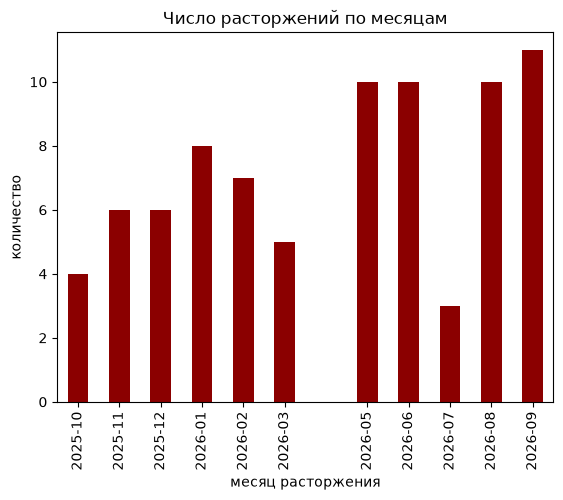

In [168]:
clients.dropna(subset=['churn_date']).groupby(
    clients['churn_date'].dt.to_period('M'))['client_id'].count().plot(kind='bar', color='darkred')

plt.title('Число расторжений по месяцам')
plt.xlabel('месяц расторжения')
plt.ylabel('количество')
plt.show()

Уходы распределены по всему периоду с октября 2025 года, в апреле 2026 года уходов нет.
Это важно для разбиения по времени: в каждую выборку должно попасть достаточно уходов

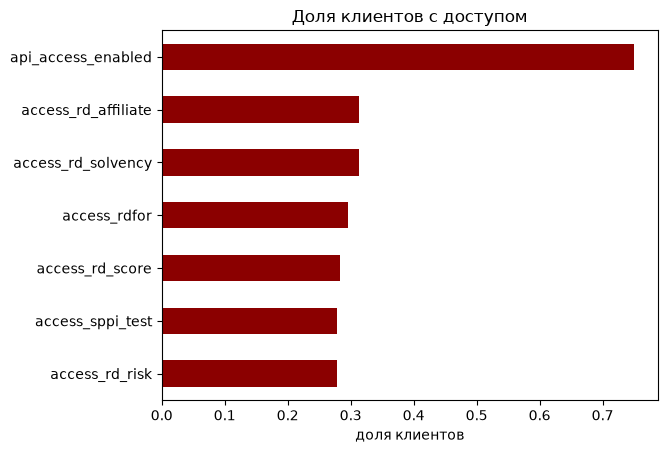

In [169]:
access_cols = ['access_rd_risk', 'access_rd_solvency', 'access_rdfor',
               'access_rd_score', 'access_rd_affiliate', 'access_sppi_test']
clients['n_products_access'] = clients[access_cols].sum(axis=1)

clients[['api_access_enabled'] + access_cols].mean().sort_values().plot(kind='barh', color='darkred')

plt.title('Доля клиентов с доступом')
plt.xlabel('доля клиентов')
plt.show()

In [170]:
clients.groupby('n_products_access')['is_churned'].agg(['count', 'mean'])

,count,mean
n_products_access,,
0,80,0.250000
1,95,0.189474
2,122,0.204918
3,61,0.196721
4,31,0.129032
5,9,0.111111
6,2,0.000000


Чем больше продуктов подключено, тем реже клиент уходит: 25% без продуктов против
11–13% у клиентов с 4–5 продуктами. Групп с 5–6 продуктами мало, выводы по ним ненадёжны

### Дневная активность клиентов

В таблицах активности хранятся только дни с ненулевыми запросами или сессиями.
Для признаков нужна полная дневная история, поэтому:
- для каждого клиента построим календарь дней обслуживания: от начала договора
  (но не раньше начала выгрузки) до дня перед расторжением (но не позже конца выгрузки);
- присоединим к нему суммарную активность за день;
- дни без строк заполним нулями — это дни без активности действующего клиента.

Дни до договора и после расторжения нулями не заполняем: клиента в это время не было.

In [171]:
start = clients['contract_start_date'].clip(lower=DATA_START)
end = (clients['churn_date'] - pd.Timedelta(days=1)).fillna(DATA_END).clip(upper=DATA_END)

calendar = pd.concat([pd.DataFrame({'client_id': client_id, 'date': pd.date_range(s, e)})
                      for client_id, s, e in zip(clients['client_id'], start, end)],
                     ignore_index=True)
calendar.shape

(199622, 2)

In [172]:
# активность за день: сумма запросов и число разных ручек, сумма сессий и число разных продуктов
api_daily = api_usage.groupby(['client_id', 'date']).agg(
    api_requests=('requests_count', 'sum'),
    api_endpoints=('endpoint_id', 'nunique')).reset_index()

product_daily = product_usage.groupby(['client_id', 'date']).agg(
    product_sessions=('sessions_count', 'sum'),
    products_used=('product_id', 'nunique')).reset_index()

daily = calendar.merge(api_daily, on=['client_id', 'date'], how='left')
daily = daily.merge(product_daily, on=['client_id', 'date'], how='left')

activity_cols = ['api_requests', 'api_endpoints', 'product_sessions', 'products_used']
daily[activity_cols] = daily[activity_cols].fillna(0).astype(int)
daily['is_active'] = ((daily['api_requests'] > 0) | (daily['product_sessions'] > 0)).astype(int)

daily = daily.sort_values(['client_id', 'date'], ignore_index=True)

Проверим, что вся активность попала в дни обслуживания: суммы в дневной таблице
должны совпадать с исходными таблицами

In [173]:
display(daily['api_requests'].sum() == api_usage['requests_count'].sum())
display(daily['product_sessions'].sum() == product_usage['sessions_count'].sum())

np.True_

np.True_

### Активность перед уходом

Главный вопрос задачи — есть ли сигнал за 14–28 дней до расторжения.
Клиенты сильно различаются по объёму (у одних тысячи запросов в день, у других единицы),
поэтому сравниваем активность каждого клиента с его же средним уровнем

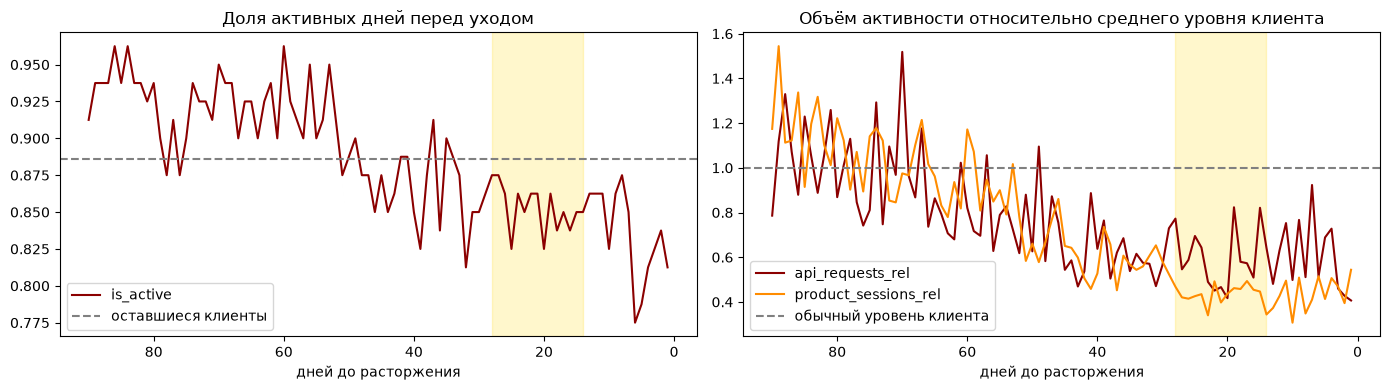

In [174]:
# сколько дней осталось до расторжения (у неушедших — пропуск)
daily = daily.merge(clients[['client_id', 'churn_date']], on='client_id', how='left')
daily['days_to_churn'] = (daily['churn_date'] - daily['date']).dt.days

for col in ['api_requests', 'product_sessions']:
    daily[f'{col}_rel'] = daily[col] / daily.groupby('client_id')[col].transform('mean')

before_churn = daily[daily['days_to_churn'].between(1, 90)].groupby('days_to_churn')[
    ['is_active', 'api_requests_rel', 'product_sessions_rel']].mean()

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 4))

before_churn['is_active'].plot(ax=axes[0], color='darkred')
axes[0].axhline(daily.loc[daily['days_to_churn'].isna(), 'is_active'].mean(),
                color='gray', linestyle='--', label='оставшиеся клиенты')
axes[0].set_title('Доля активных дней перед уходом')

before_churn[['api_requests_rel', 'product_sessions_rel']].plot(ax=axes[1],
                                                                 color=['darkred', 'darkorange'])
axes[1].axhline(1, color='gray', linestyle='--', label='обычный уровень клиента')
axes[1].set_title('Объём активности относительно среднего уровня клиента')

for ax in axes:
    ax.axvspan(WARNING_MIN_DAYS, HORIZON_DAYS, color='gold', alpha=0.2)
    ax.invert_xaxis()
    ax.set_xlabel('дней до расторжения')
    ax.legend()

plt.tight_layout()
plt.show()

daily = daily.drop(columns=['churn_date', 'days_to_churn', 'api_requests_rel', 'product_sessions_rel'])

Уходящие клиенты почти не перестают заходить: доля активных дней падает лишь
с ~89% до ~85%. Зато падает объём работы относительно их собственного уровня:
примерно за 56 дней до ухода запросы к API опускаются до ~60% от обычного,
сессии в продуктах — до ~45%. Значит, главные признаки — не абсолютные счётчики,
а активность относительно личной нормы клиента

## Создание новых признаков

Одна строка итоговой таблицы — клиент на утро даты прогноза `date`.
Прогноз делается утром, поэтому активность текущего дня ещё неизвестна:
все признаки считаем по дням **до** `date`.

Новые признаки:
- `history_days` — сколько дней истории клиента есть до даты прогноза (от начала договора, но не раньше начала выгрузки);
- суммы запросов, сессий и активных дней за 7 / 14 / 28 / 56 дней;
- сколько разных ручек API и продуктов клиент в среднем использует в день за те же окна (`*_mean`);
- тренд: последняя неделя против средней недели за 28 дней (1 — без изменений, меньше 1 — спад);
- активность за последние 28 дней относительно личной нормы клиента — средней активности
  за дни 29–112 до прогноза (1 — как обычно, 0.6 — на 40% ниже обычного);
- `days_without_activity`, `days_without_api`, `days_without_product` — сколько дней прошло
  с последней активности (общей, по API, по продуктам);
- `contract_days` — сколько дней действует договор; доступы и число подключённых продуктов.

Порядок расчёта:
1. Убираем текущий день (`shift(1)`) и по прошлым дням считаем суммы за окна
   (`rolling`) и дату последней активности.
2. Из сумм считаем средние, тренды и отношение к норме.
3. Убираем первые 28 дней каждого клиента — по ним окно за 28 дней ещё неполное.

In [175]:
# сортируем по клиенту и дате: rolling, shift и ffill ниже идут по строкам по порядку
panel = daily.sort_values(['client_id', 'date'], ignore_index=True)

# сколько дней истории есть до даты прогноза: от начала договора,
# но не раньше начала выгрузки (раньше логов активности нет)
panel = panel.merge(clients[['client_id', 'contract_start_date']], on='client_id', how='left')
panel['history_start'] = panel['contract_start_date'].clip(lower=DATA_START)
panel['history_days'] = (panel['date'] - panel['history_start']).dt.days

# суммы за окна 7 / 14 / 28 / 56 дней — признаки модели,
# и за 112 дней — только чтобы ниже посчитать личную норму клиента (в модель не идёт).
# shift(1) — сначала убираем текущий день (берём только прошлые дни),
# rolling(w).sum() — потом суммируем последние w из них
for w in WINDOWS + [BASELINE_DAYS]:
    for col in ['api_requests', 'product_sessions', 'is_active', 'api_endpoints', 'products_used']:
        panel[f'{col}_{w}d'] = panel.groupby('client_id')[col].transform(
            lambda x: x.shift(1).rolling(w, min_periods=1).sum())

# дата последнего дня с активностью (общей, по API, по продуктам) — тоже только по прошлым дням
for name, col in [('activity', 'is_active'), ('api', 'api_requests'), ('product', 'product_sessions')]:
    panel[f'last_{name}_date'] = panel['date'].where(panel[col] > 0)
    panel[f'last_{name}_date'] = panel.groupby('client_id')[f'last_{name}_date'].transform(
        lambda x: x.shift(1).ffill())

In [176]:
# признаки по окнам
for w in WINDOWS:
    panel = panel.rename(columns={f'is_active_{w}d': f'active_days_{w}d'})
    # среднее в день: делим на число дней в окне (в начале истории окно короче)
    panel[f'api_endpoints_{w}d_mean'] = panel[f'api_endpoints_{w}d'] / panel['history_days'].clip(upper=w)
    panel[f'products_used_{w}d_mean'] = panel[f'products_used_{w}d'] / panel['history_days'].clip(upper=w)

# тренд: последняя неделя против средней недели за 28 дней (если активности не было — 1)
for col in ['api_requests', 'product_sessions', 'active_days']:
    panel[f'{col}_trend_7_28'] = (panel[f'{col}_7d'] / (panel[f'{col}_28d'] / 4)).fillna(1)

In [177]:
# активность относительно личной нормы: среднее в день за последние 28 дней
# против среднего в день за дни 29–112 (у клиентов с короткой историей этот период короче)
last_days = panel['history_days'].clip(upper=28)  # сколько дней в последнем окне
norm_days = panel['history_days'].clip(upper=BASELINE_DAYS) - last_days  # сколько дней в периоде нормы

for col in ['api_requests', 'api_endpoints', 'product_sessions', 'products_used']:
    last_28 = panel[f'{col}_28d'] / last_days
    norm = (panel[f'{col}_{BASELINE_DAYS}d'] - panel[f'{col}_28d']) / norm_days
    panel[f'{col}_vs_norm'] = last_28 / norm
    # если норма меньше чем за 28 дней или нулевая — сравнивать не с чем, ставим 1
    panel.loc[(norm_days < 28) | (norm == 0), f'{col}_vs_norm'] = 1

In [178]:
# сколько дней прошло с последней активности (если её ещё не было — вся история)
for name in ['activity', 'api', 'product']:
    panel[f'days_without_{name}'] = (panel['date'] - panel[f'last_{name}_date']).dt.days
    panel[f'days_without_{name}'] = panel[f'days_without_{name}'].fillna(panel['history_days'])

# срок договора и доступы клиента
panel = panel.merge(clients[['client_id', 'api_access_enabled', 'n_products_access'] + access_cols],
                    on='client_id', how='left')
panel['contract_days'] = (panel['date'] - panel['contract_start_date']).dt.days

In [179]:
# удаляем значения текущего дня (будущее для утреннего прогноза) и вспомогательные колонки
panel = panel.drop(columns=['api_requests', 'product_sessions', 'is_active', 'api_endpoints',
                            'products_used', 'contract_start_date', 'history_start',
                            'last_activity_date', 'last_api_date', 'last_product_date'])
panel = panel.drop(columns=[f'{col}_{w}d' for w in WINDOWS for col in ['api_endpoints', 'products_used']])
panel = panel.drop(columns=[f'{col}_{BASELINE_DAYS}d' for col in
                            ['api_requests', 'product_sessions', 'is_active', 'api_endpoints', 'products_used']])

# оставляем даты, где у клиента уже есть 28 дней истории
panel = panel[panel['history_days'] >= MIN_HISTORY_DAYS].reset_index(drop=True)
panel.shape

(188422, 42)

Проверим отсутствие утечки на случайной строке: запросы за 7 дней должны совпадать
с ручным расчётом по 7 дням строго до даты прогноза

In [180]:
row = panel.sample(1, random_state=rand_state).iloc[0]
mask = ((daily['client_id'] == row['client_id']) & (daily['date'] < row['date'])
        & (daily['date'] >= row['date'] - pd.Timedelta(days=7)))

display(f'{row["client_id"]}, {row["date"].date()}: в таблице {row["api_requests_7d"]:.0f}, '
        f'вручную {daily.loc[mask, "api_requests"].sum()}')

'C323, 2026-04-22: в таблице 91, вручную 91'

### Формирование целевой переменной

Таргет для каждой пары (клиент, дата прогноза):
- 1 — договор расторгнут в течение 28 дней после даты прогноза
  (`churn_date` — первый день без обслуживания, поэтому уход «завтра» — это 1 день);
- 0 — все 28 дней после даты прогноза наблюдались и расторжения не было;
- пропуск — наблюдение закончилось раньше, исход неизвестен. Такие строки в обучение не идут:
  отсутствие зарегистрированного ухода ещё не значит, что клиент не уйдёт

Дату расторжения используем только для таргета, в признаки она не попадает.
Колонка `days_to_churn` (сколько дней осталось до ухода) — служебная: она нужна только
для метрики early_recall (была ли тревога за 14–28 дней до ухода), в признаки модели не входит

In [181]:
panel = panel.merge(clients[['client_id', 'churn_date', 'outcome_observed_until']],
                    on='client_id', how='left')
panel['days_to_churn'] = (panel['churn_date'] - panel['date']).dt.days

mask_1 = panel['days_to_churn'].between(1, HORIZON_DAYS)
mask_0 = ~mask_1 & (panel['date'] + pd.Timedelta(days=HORIZON_DAYS) <= panel['outcome_observed_until'])

panel['target'] = np.nan
panel.loc[mask_0, 'target'] = 0
panel.loc[mask_1, 'target'] = 1

panel = panel.drop(columns=['churn_date', 'outcome_observed_until'])

## Анализ итоговой таблицы

In [182]:
panel.head()

,client_id,date,history_days,api_requests_7d,product_sessions_7d,active_days_7d,api_requests_14d,product_sessions_14d,active_days_14d,api_requests_28d,product_sessions_28d,active_days_28d,api_requests_56d,product_sessions_56d,active_days_56d,api_endpoints_7d_mean,products_used_7d_mean,api_endpoints_14d_mean,products_used_14d_mean,api_endpoints_28d_mean,products_used_28d_mean,api_endpoints_56d_mean,products_used_56d_mean,api_requests_trend_7_28,product_sessions_trend_7_28,active_days_trend_7_28,api_requests_vs_norm,api_endpoints_vs_norm,product_sessions_vs_norm,products_used_vs_norm,days_without_activity,days_without_api,days_without_product,api_access_enabled,n_products_access,access_rd_risk,access_rd_solvency,access_rdfor,access_rd_score,access_rd_affiliate,access_sppi_test,contract_days,days_to_churn,target
0,C001,2025-04-29,28,1981.0,9.0,7.0,2008.0,17.0,14.0,5123.0,38.0,28.0,5123.0,38.0,28.0,4.142857,0.714286,3.357143,0.714286,3.535714,0.821429,3.535714,0.821429,1.546750,0.947368,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1,4,1,1,1,1,0,0,742,181.0,0.0
1,C001,2025-04-30,29,1983.0,8.0,7.0,2006.0,17.0,14.0,5124.0,35.0,28.0,5126.0,39.0,29.0,4.428571,0.714286,3.214286,0.714286,3.571429,0.821429,3.517241,0.827586,1.548009,0.914286,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1,4,1,1,1,1,0,0,743,180.0,0.0
2,C001,2025-05-01,30,32.0,6.0,7.0,2007.0,14.0,14.0,5121.0,35.0,28.0,5127.0,40.0,30.0,3.428571,0.714286,3.285714,0.714286,3.535714,0.821429,3.433333,0.833333,0.024995,0.685714,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1,4,1,1,1,1,0,0,744,179.0,0.0
3,C001,2025-05-02,31,38.0,7.0,7.0,2021.0,13.0,14.0,3614.0,36.0,28.0,5142.0,41.0,31.0,3.571429,0.857143,3.714286,0.642857,3.500000,0.857143,3.548387,0.838710,0.042059,0.777778,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1,4,1,1,1,1,0,0,745,178.0,0.0
4,C001,2025-05-03,32,40.0,10.0,7.0,2020.0,17.0,14.0,3616.0,37.0,28.0,5147.0,45.0,32.0,4.000000,1.000000,3.785714,0.785714,3.571429,0.892857,3.593750,0.875000,0.044248,1.081081,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1,4,1,1,1,1,0,0,746,177.0,0.0


In [183]:
panel['target'].value_counts(normalize=True, dropna=False)

target
0.0    0.940559
NaN    0.047553
1.0    0.011888
Name: proportion, dtype: float64

In [184]:
display(f'Дубликатов пары клиент + дата: {panel.duplicated(subset=["client_id", "date"]).sum()}')
display(f'Пропусков в признаках: {panel.drop(columns=["target", "days_to_churn"]).isna().sum().sum()}')

'Дубликатов пары клиент + дата: 0'

'Пропусков в признаках: 0'

**Вывод:** итоговая таблица — 188 422 строки (клиент × дата прогноза) по 400 клиентам, пропусков
и дубликатов нет. Классы сильно несбалансированы: target=1 — около 1,2% строк, target=0 — около 94%.
Ещё около 4,8% строк — последние 28 дней выгрузки у неушедших клиентов, их исход неизвестен,
в обучение и оценку они не идут. Дисбаланс учитываем балансировкой классов и метрикой PR-AUC

## Моделирование

Подготовим выборки по времени:
- **train** — до `TRAIN_END`: обучение и кросс-валидация с подбором параметров;
- **valid** — `VALID_MONTHS` месяца до `VALID_END`: выбор порога тревоги;
- **test** — последние `TEST_MONTHS` месяца выгрузки: финальная проверка (OOT-выборка).

Последние 28 дней train и valid удаляем: их таргет заглядывает в следующую выборку.
Строки с неизвестным исходом удаляем

In [185]:
labeled = panel.dropna(subset=['target']).sort_values(['date', 'client_id'], ignore_index=True)
gap = pd.Timedelta(days=HORIZON_DAYS)

train = labeled[labeled['date'] <= TRAIN_END - gap]
valid = labeled[(labeled['date'] > TRAIN_END) & (labeled['date'] <= VALID_END - gap)]
test = labeled[labeled['date'] > VALID_END]

for name, df in [('train', train), ('valid', valid), ('test', test)]:
    display(f'{name}: {df["date"].min().date()} — {df["date"].max().date()}, строк {df.shape[0]}, '
            f'доля target=1 {df["target"].mean():.2%}, '
            f'уходов {df.loc[df["target"] == 1, "client_id"].nunique()}')

'train: 2025-04-29 — 2026-04-02, строк 125820, доля target=1 0.80%, уходов 36'

'valid: 2026-05-01 — 2026-07-02, строк 22253, доля target=1 1.84%, уходов 20'

'test: 2026-07-31 — 2026-09-29, строк 11565, доля target=1 4.21%, уходов 21'

Разделим признаки по типам для пайплайна предобработки:
- суммы запросов и сессий, дни без активности и срок договора сильно скошены (у одних клиентов тысячи запросов, у других единицы) — логарифмируем и масштабируем;
- остальные числовые признаки — только масштабируем;
- флаги доступов — без изменений

`history_days` в модель не берём. У клиентов, заключивших договор до апреля 2025 года, он
равен числу дней с начала выгрузки, то есть фактически это дата прогноза (корреляция с датой
в train ~0.97). А уходы в данных начинаются только с октября 2025 года — модель выучила бы
правило «чем позже дата, тем выше риск», которое на новых данных не работает.
Реальный срок жизни клиента описывает `contract_days`

In [186]:
binary_features = ['api_access_enabled'] + access_cols

num_features_log = ([f'api_requests_{w}d' for w in WINDOWS] + [f'product_sessions_{w}d' for w in WINDOWS]
                    + ['days_without_activity', 'days_without_api', 'days_without_product',
                       'contract_days'])

num_features = ([f'active_days_{w}d' for w in WINDOWS]
                + [f'api_endpoints_{w}d_mean' for w in WINDOWS]
                + [f'products_used_{w}d_mean' for w in WINDOWS]
                + ['api_requests_trend_7_28', 'product_sessions_trend_7_28', 'active_days_trend_7_28']
                + ['api_requests_vs_norm', 'api_endpoints_vs_norm',
                   'product_sessions_vs_norm', 'products_used_vs_norm']
                + ['n_products_access'])

feature_cols = num_features_log + num_features + binary_features
len(feature_cols)

39

In [187]:
X_train, y_train = train[feature_cols], train['target']
X_valid, y_valid = valid[feature_cols], valid['target']
X_test, y_test = test[feature_cols], test['target']

groups_idx = (train['date'] - train['date'].min()).dt.days.to_numpy()  # номер дня для деления на фолды

Напишем пайплайн предобработки данных

In [188]:
num_pipe_log = Pipeline(steps=[
    ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
    ('scaler', StandardScaler())
])

num_pipe = Pipeline(steps=[
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer(transformers=[
    ('num_log', num_pipe_log, num_features_log),
    ('num', num_pipe, num_features),
    ('binary', 'passthrough', binary_features)
], verbose_feature_names_out=False)

Напишем пайплайны для обучения базовых моделей:
- логистическая регрессия без балансировки;
- логистическая регрессия с балансировкой (class_weight='balanced');
- CatBoost без балансировки;
- CatBoost с балансировкой (auto_class_weights='Balanced').

CatBoost масштабирование не нужно, поэтому используем модель напрямую, без пайплайна
(у неё те же методы fit и predict_proba)

In [189]:
pipe_logreg = Pipeline(steps=[
    ('prep', preprocessor),
    ('model', LogisticRegression(max_iter=2000))
])

pipe_logreg_cw = Pipeline(steps=[
    ('prep', preprocessor),
    ('model', LogisticRegression(class_weight='balanced', max_iter=2000))
])

pipe_catboost = CatBoostClassifier(random_seed=rand_state, iterations=300, verbose=0)

pipe_catboost_cw = CatBoostClassifier(random_seed=rand_state, iterations=300,
                                      auto_class_weights='Balanced', verbose=0)

pipes = [pipe_logreg, pipe_logreg_cw, pipe_catboost, pipe_catboost_cw]
pipes_names = ['pipe_logreg', 'pipe_logreg_cw', 'pipe_catboost', 'pipe_catboost_cw']

Опишем функцию для расчёта метрик:
- ROC-AUC и PR-AUC — по клиенто-дням;
- early_recall — доля ушедших клиентов, по которым была хотя бы одна тревога
  (прогноз выше порога) за 14–28 дней до ухода;
- false_alert_rate — доля неушедших клиентов, получивших хотя бы одну тревогу.

Последние две метрики считаются по клиентам, поэтому функции нужна вся выборка,
а не только y

In [190]:
def metrics(df, y_proba, threshold):
    ROC_AUC = roc_auc_score(df['target'], y_proba)
    PR_AUC = average_precision_score(df['target'], y_proba)

    alerts = df[['client_id', 'target', 'days_to_churn']].assign(alert=y_proba >= threshold)
    churned = alerts[alerts['target'] == 1]
    early = churned[churned['days_to_churn'].between(WARNING_MIN_DAYS, HORIZON_DAYS)]
    retained = alerts[~alerts['client_id'].isin(churned['client_id'])]

    # early_recall
    early_recall = early.groupby('client_id')['alert'].any().mean()
    # false_alert_rate
    false_alert_rate = retained.groupby('client_id')['alert'].any().mean()

    return ROC_AUC, PR_AUC, early_recall, false_alert_rate

Кросс-валидация по времени: фолды идут по дням, valid-часть каждого фолда — 45 дней,
между train и valid фолда зазор 28 дней (горизонт таргета). Уходы в данных начинаются
только с октября 2025 года, поэтому фолдов три и они короткие — иначе в первом фолде
не окажется ни одного ухода

In [191]:
gtscv = GroupTimeSeriesSplit(n_splits=3, test_size=45, shift_size=45, gap_size=HORIZON_DAYS,
                             window_type='expanding')

In [192]:
res = []
for pipe, p_name in zip(pipes, pipes_names):

    # список для сбора метрик по фолдам
    fold_metr = []

    # индексы для тренировочной и валидационной части в каждом из 3 фолдов
    for train_idx, val_idx in gtscv.split(X_train, y_train, groups=groups_idx):

        # выборки по индексам
        X_t, X_v = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_t, y_v = y_train.iloc[train_idx], y_train.iloc[val_idx]

        # обучение и предсказания
        pipe.fit(X_t, y_t)
        y_proba = pipe.predict_proba(X_v)[:, 1]

        fold_metr.append({'ROC_AUC': roc_auc_score(y_v, y_proba),
                          'PR_AUC': average_precision_score(y_v, y_proba)})

    # усредняем
    res.append({'model': p_name, **pd.DataFrame(fold_metr).mean().to_dict()})

df_results = pd.DataFrame(res)
display(df_results)

,model,ROC_AUC,PR_AUC
0,pipe_logreg,0.837689,0.257401
1,pipe_logreg_cw,0.809452,0.178563
2,pipe_catboost,0.819277,0.083482
3,pipe_catboost_cw,0.752840,0.074944


**Вывод:** на кросс-валидации лучше всех логистическая регрессия без балансировки
(ROC-AUC 0.838, PR-AUC 0.257), CatBoost с настройками по умолчанию — 0.819.
Балансировка классов по ROC-AUC не помогает ни одной модели: ранжирование клиентов от неё почти
не зависит, она лишь сдвигает вероятности вверх. Порог тревоги мы всё равно подбираем отдельно,
поэтому дальше оставляем балансировку — так у моделей одинаковая шкала вероятностей.
Уходов в train мало (36), поэтому важна сильная регуляризация — её и подберём через optuna

### Подбор гиперпараметров

Подберём параметры обеих моделей с помощью optuna, максимизируя средний ROC-AUC
на кросс-валидации. Для логистической регрессии — сила регуляризации C,
для CatBoost — число деревьев, глубина, скорость обучения и регуляризация

In [193]:
def cv_roc_auc(pipe):
    # средний ROC-AUC модели (или пайплайна) на кросс-валидации по времени
    fold_metr = []
    for train_idx, val_idx in gtscv.split(X_train, y_train, groups=groups_idx):
        X_t, X_v = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_t, y_v = y_train.iloc[train_idx], y_train.iloc[val_idx]
        pipe.fit(X_t, y_t)
        fold_metr.append(roc_auc_score(y_v, pipe.predict_proba(X_v)[:, 1]))
    return np.mean(fold_metr)

In [194]:
def objective_lr(trial):
    params_lr = {
        'C': trial.suggest_float('C', 1e-3, 10, log=True)
    }
    ppln_lr = Pipeline(steps=[
        ('prep', preprocessor),
        ('model', LogisticRegression(class_weight='balanced', max_iter=2000, **params_lr))
    ])
    return cv_roc_auc(ppln_lr)


sampler_lr = optuna.samplers.TPESampler(seed=rand_state)
study_lr = optuna.create_study(direction='maximize', sampler=sampler_lr)
study_lr.optimize(objective_lr, n_trials=30, show_progress_bar=True)

  0%|          | 0/30 [00:00<?, ?it/s]

In [195]:
display('Optuna для LogisticRegression')
display(f'Лучшие параметры: {study_lr.best_params}')
display(f'Лучшее значение ROC_AUC: {study_lr.best_value}')

'Optuna для LogisticRegression'

"Лучшие параметры: {'C': 0.0010177147839125955}"

'Лучшее значение ROC_AUC: 0.8709934136289664'

In [196]:
def objective_cb(trial):
    params_cb = {
        'iterations': trial.suggest_int('iterations', 100, 500),
        'depth': trial.suggest_int('depth', 3, 8),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1, 10)
    }
    model_cb = CatBoostClassifier(random_seed=rand_state, auto_class_weights='Balanced',
                                  verbose=0, **params_cb)
    return cv_roc_auc(model_cb)


sampler_cb = optuna.samplers.TPESampler(seed=rand_state)
study_cb = optuna.create_study(direction='maximize', sampler=sampler_cb)
study_cb.optimize(objective_cb, n_trials=30, show_progress_bar=True)

  0%|          | 0/30 [00:00<?, ?it/s]

In [197]:
display('Optuna для CatBoost')
display(f'Лучшие параметры: {study_cb.best_params}')
display(f'Лучшее значение ROC_AUC: {study_cb.best_value}')

'Optuna для CatBoost'

"Лучшие параметры: {'iterations': 234, 'depth': 3, 'learning_rate': 0.01079067695213541, 'l2_leaf_reg': 9.282598472395403}"

'Лучшее значение ROC_AUC: 0.8099955346126402'

Обучим модели с лучшими параметрами на всём train

In [198]:
pipe_lr_opt = Pipeline(steps=[
    ('prep', preprocessor),
    ('model', LogisticRegression(class_weight='balanced', max_iter=2000, **study_lr.best_params))
])
pipe_cb_opt = CatBoostClassifier(random_seed=rand_state, auto_class_weights='Balanced',
                                 verbose=0, **study_cb.best_params)

pipe_lr_opt.fit(X_train, y_train)
pipe_cb_opt.fit(X_train, y_train)

CatBoostClassifier(auto_class_weights='Balanced', depth=3, iterations=234, l2_leaf_reg=9.282598472395403, learning_rate=0.01079067695213541, random_seed=42, verbose=0)

## Поиск порога тревоги

Порог подбираем на valid. Чтобы не гадать с абсолютными значениями вероятностей,
перебираем пороги как квантили прогноза: порог «95%» означает, что тревога
поднимается по 5% клиенто-дней с самым высоким риском (alert_share)

In [199]:
threshold_metrics = []
for pipe, p_name in zip([pipe_lr_opt, pipe_cb_opt], ['logreg_optuna', 'catboost_optuna']):
    valid_proba = pipe.predict_proba(X_valid)[:, 1]
    for q in [0.80, 0.85, 0.90, 0.93, 0.95, 0.97, 0.99]:
        t = np.quantile(valid_proba, q)
        ROC_AUC, PR_AUC, early_recall, false_alert_rate = metrics(valid, valid_proba, t)
        threshold_metrics.append({'model': p_name,
                                  'alert_share': 1 - q,
                                  'threshold': t,
                                  'ROC_AUC': ROC_AUC,
                                  'PR_AUC': PR_AUC,
                                  'early_recall': early_recall,
                                  'false_alert_rate': false_alert_rate})

df_thresholds = pd.DataFrame(threshold_metrics)
display(df_thresholds)

,model,alert_share,threshold,ROC_AUC,PR_AUC,early_recall,false_alert_rate
0,logreg_optuna,0.20,0.486602,0.881710,0.293228,0.866667,0.654070
1,logreg_optuna,0.15,0.558098,0.881710,0.293228,0.866667,0.569767
2,logreg_optuna,0.10,0.647561,0.881710,0.293228,0.800000,0.453488
3,logreg_optuna,0.07,0.725953,0.881710,0.293228,0.733333,0.311047
4,logreg_optuna,0.05,0.793480,0.881710,0.293228,0.666667,0.206395
5,logreg_optuna,0.03,0.890212,0.881710,0.293228,0.533333,0.107558
6,logreg_optuna,0.01,0.983999,0.881710,0.293228,0.333333,0.023256
7,catboost_optuna,0.20,0.320370,0.877903,0.245964,0.866667,0.619186
8,catboost_optuna,0.15,0.391501,0.877903,0.245964,0.866667,0.511628
9,catboost_optuna,0.10,0.485320,0.877903,0.245964,0.866667,0.360465


Выберем модель и порог: максимум разницы early_recall − false_alert_rate
(ловим больше уходов при меньшем числе ложных тревог)

In [200]:
best = df_thresholds.loc[(df_thresholds['early_recall'] - df_thresholds['false_alert_rate']).idxmax()]
display(best)

best_pipe = pipe_lr_opt if best['model'] == 'logreg_optuna' else pipe_cb_opt
best_threshold = best['threshold']

model               catboost_optuna
alert_share                    0.07
threshold                  0.607979
ROC_AUC                    0.877903
PR_AUC                     0.245964
early_recall                    0.8
false_alert_rate           0.267442
Name: 10, dtype: object

**Вывод:** после подбора параметров на кросс-валидации лучше логистическая регрессия
(ROC-AUC 0.871 против 0.810 у CatBoost); обе модели выбрали сильную регуляризацию
(C ≈ 0.001 у логрегрессии, неглубокие деревья depth=3 у CatBoost).

На valid модели почти равны по ROC-AUC (0.882 и 0.878). По критерию early_recall − false_alert_rate
выбран **CatBoost с бюджетом тревог 7% клиенто-дней (порог 0.608)**: 80% уходов (12 из 15)
пойманы за 14–28 дней, ложные тревоги получили 27% неушедших клиентов. У логрегрессии при том же
бюджете — 73% и 31%. Разница между моделями — один-два клиента, то есть в пределах случайности,
поэтому логрегрессия остаётся равноценной и более интерпретируемой альтернативой

## Проверка на тестовой выборке

Модель обучена на train, порог выбран на valid — test модель не видела

In [201]:
y_proba_test = best_pipe.predict_proba(X_test)[:, 1]
ROC_AUC_test, PR_AUC_test, early_recall_test, false_alert_rate_test = metrics(test, y_proba_test,
                                                                              best_threshold)

display(pd.DataFrame({'ROC_AUC': ROC_AUC_test,
                      'PR_AUC': PR_AUC_test,
                      'early_recall': early_recall_test,
                      'false_alert_rate': false_alert_rate_test}, index=[best['model']]))

,ROC_AUC,PR_AUC,early_recall,false_alert_rate
catboost_optuna,0.874664,0.381463,0.722222,0.215625


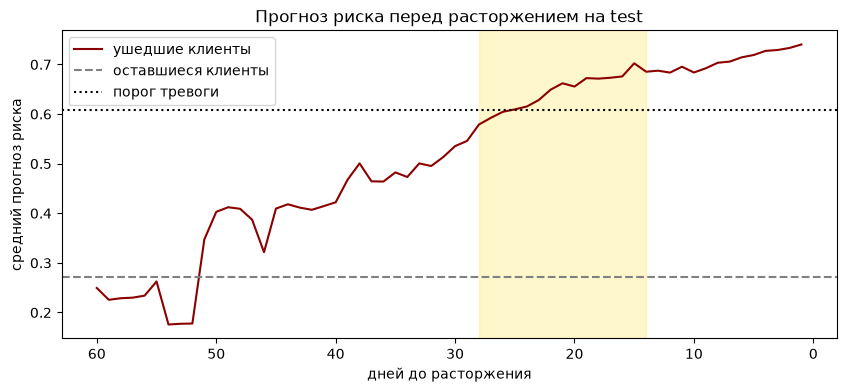

In [202]:
test_risk = test.assign(risk=y_proba_test)
risk_before_churn = test_risk[test_risk['days_to_churn'] <= 60].groupby('days_to_churn')['risk'].mean()

risk_before_churn.plot(color='darkred', figsize=(10, 4), label='ушедшие клиенты')
plt.axhline(test_risk.loc[test_risk['days_to_churn'].isna(), 'risk'].mean(),
            color='gray', linestyle='--', label='оставшиеся клиенты')
plt.axhline(best_threshold, color='black', linestyle=':', label='порог тревоги')
plt.axvspan(WARNING_MIN_DAYS, HORIZON_DAYS, color='gold', alpha=0.2)
plt.gca().invert_xaxis()
plt.title('Прогноз риска перед расторжением на test')
plt.xlabel('дней до расторжения')
plt.ylabel('средний прогноз риска')
plt.legend()
plt.show()

**Вывод:** на test CatBoost показывает ROC-AUC 0.875 (на valid 0.878) и PR-AUC 0.381 —
при доле положительного класса 4,2% это примерно в 9 раз лучше случайной модели.
За 14–28 дней до ухода пойманы 72% уходов (13 из 18), ложные тревоги получили 22% неушедших
клиентов (69 из 320). Качество на test практически совпадает с valid — модель стабильна
и не переобучена. Колебания early_recall между выборками (80% → 72%) — это один-два клиента
при 15–18 уходах в выборке

### Разбор ошибок

По каждому ушедшему клиенту из test смотрим, была ли тревога за 14–28 дней до ухода
и какой был максимальный риск в этот период

In [203]:
early = test_risk[test_risk['days_to_churn'].between(WARNING_MIN_DAYS, HORIZON_DAYS)]

churn_check = early.groupby('client_id').agg(max_risk=('risk', 'max'))
churn_check['alert'] = churn_check['max_risk'] >= best_threshold
display(churn_check.sort_values('max_risk'))

,max_risk,alert
client_id,,
C324,0.221681,False
C034,0.289592,False
C157,0.530557,False
C181,0.565936,False
C078,0.592551,False
C042,0.708595,True
C023,0.744702,True
C028,0.748067,True
C224,0.821992,True


Сравним пойманные и пропущенные уходы по признакам активности относительно нормы:
если у пропущенных активность не падала, модель их и не могла заметить

In [204]:
norm_cols = ['api_requests_vs_norm', 'api_endpoints_vs_norm', 'product_sessions_vs_norm', 'products_used_vs_norm']

early_check = early.merge(churn_check[['alert']], on='client_id')
display(early_check.groupby('alert')[norm_cols].mean())

,api_requests_vs_norm,api_endpoints_vs_norm,product_sessions_vs_norm,products_used_vs_norm
alert,,,,
False,0.951517,0.991988,0.702916,0.874837
True,0.677463,0.848417,0.578148,0.734653


Ложные тревоги: клиенты, которые не ушли, но получили хотя бы одну тревогу.
Сравним их с остальными неушедшими клиентами

In [205]:
retained = test_risk[test_risk['days_to_churn'].isna()].copy()
retained['alert'] = retained['risk'] >= best_threshold
false_alert_clients = retained.loc[retained['alert'], 'client_id'].unique()

display(f'Неушедших клиентов в test: {retained["client_id"].nunique()}, '
        f'из них с ложной тревогой: {len(false_alert_clients)}')
display(retained.groupby(retained['client_id'].isin(false_alert_clients))[norm_cols].mean())

'Неушедших клиентов в test: 320, из них с ложной тревогой: 69'

,api_requests_vs_norm,api_endpoints_vs_norm,product_sessions_vs_norm,products_used_vs_norm
client_id,,,,
False,1.028991,1.002535,0.964792,1.002916
True,0.890977,0.979384,0.745868,0.830077


**Вывод:** пропущено 5 уходов из 18. У пропущенных клиентов запросы к API в последний месяц
почти на уровне нормы (0.95), тогда как у пойманных упали до 0.68; сессии в продуктах падают у обеих
групп (0.70 и 0.58). Модель хуже замечает уход, когда клиент сохраняет работу через API, а также
уходы без выраженного сигнала в активности — о таких случаях предупреждает и описание данных.

Ложные тревоги получили 69 из 320 неушедших клиентов. У них тоже просела активность: сессии
в продуктах — 0.75 от нормы против 0.96 у остальных неушедших. Это «просадки без ухода»: по активности
их не отличить от начала ухода. Для менеджера такая тревога всё равно полезна как повод
связаться с клиентом, у которого что-то изменилось

## Анализ важности признаков

In [206]:
df_importances = pd.DataFrame({
    'feature': feature_cols,
    'importance_catboost': pipe_cb_opt.get_feature_importance()
})
df_coefs = pd.DataFrame({
    'feature': pipe_lr_opt.named_steps['prep'].get_feature_names_out(),
    'coef_logreg': pipe_lr_opt.named_steps['model'].coef_[0]
})

df_importances = df_importances.merge(df_coefs, on='feature').sort_values('importance_catboost',
                                                                         ascending=False)
display(df_importances)

,feature,importance_catboost,coef_logreg
11,contract_days,14.214274,0.401452
27,api_requests_vs_norm,13.945377,-0.639594
28,api_endpoints_vs_norm,13.050950,-0.463164
29,product_sessions_vs_norm,11.666209,-0.527155
30,products_used_vs_norm,7.093103,-0.152469
35,access_rdfor,6.919948,-0.752503
10,days_without_product,3.724225,0.126197
21,products_used_14d_mean,2.964068,-0.395200
7,product_sessions_56d,2.950979,0.254339
3,api_requests_56d,2.925468,0.085421


**Вывод:** главные сигналы у обеих моделей совпадают — четыре признака активности относительно
личной нормы клиента (запросы, ручки API, сессии, продукты): чем ниже активность относительно обычной,
тем выше риск. Это совпадает с исследовательским анализом.

На первом месте у CatBoost — `contract_days` (14%), у логрегрессии его коэффициент положительный:
чем дольше договор, тем выше риск. Отчасти это может быть реальный эффект, отчасти — тот же сдвиг
во времени, что был у `history_days`: срок договора растёт вместе с датой, а доля уходов в данных
растёт к концу периода. На реальных данных этот признак нужно перепроверить.
Доступ к RDFOR снижает риск, к SPPI-тестированию — повышает.

Почти бесполезны тренды «неделя против месяца», `days_without_activity` (почти у всех клиентов это 1 день)
и часть флагов доступа — их можно убрать без потери качества

### Факторы риска для клиента

Для ежедневного отчёта менеджеру: на последнюю дату берём 10 клиентов с самым высоким риском,
отмечаем, кто выше порога тревоги, и выводим три признака, сильнее всего повышающих
риск каждого (SHAP-значения CatBoost). Это наблюдаемые сигналы модели,
а не доказанные причины ухода

In [207]:
last_day = test_risk['date'].max()
report = test_risk[test_risk['date'] == last_day].nlargest(10, 'risk')

shap_values = pipe_cb_opt.get_feature_importance(Pool(report[feature_cols]), type='ShapValues')
shap_values = pd.DataFrame(shap_values[:, :-1], columns=feature_cols, index=report.index)  # последний столбец — базовое значение

report = report[['client_id', 'date', 'risk']].copy()
report['alert'] = report['risk'] >= best_threshold
for i in range(3):
    report[f'factor_{i + 1}'] = shap_values.apply(lambda row: row.nlargest(3).index[i], axis=1)

display(f'Дата отчёта: {last_day.date()}, клиентов выше порога: {report["alert"].sum()} из 10')
display(report)

'Дата отчёта: 2026-09-29, клиентов выше порога: 1 из 10'

,client_id,date,risk,alert,factor_1,factor_2,factor_3
179461,C020,2026-09-29,0.882941,True,api_requests_vs_norm,product_sessions_vs_norm,products_used_vs_norm


## Сохранение модели

Сохраняем выбранную модель, её параметры и порог в папку `models/`.
Их использует скрипт `churn_pipeline.py` для ежедневного прогноза и переобучения

In [208]:
os.makedirs('models', exist_ok=True)
joblib.dump(best_pipe, 'models/churn_model.pkl')

model_params = {
    'model': best['model'],
    'params': study_cb.best_params if best['model'] == 'catboost_optuna' else study_lr.best_params,
    'threshold': float(best_threshold),
    'alert_share': float(best['alert_share']),
    'feature_cols': feature_cols
}
with open('models/model_params.json', 'w', encoding='utf-8') as f:
    json.dump(model_params, f, ensure_ascii=False, indent=2)

model_params

{'model': 'catboost_optuna',
 'params': {'iterations': 234,
  'depth': 3,
  'learning_rate': 0.01079067695213541,
  'l2_leaf_reg': 9.282598472395403},
 'threshold': 0.6079789064960021,
 'alert_share': 0.06999999999999995,
 'feature_cols': ['api_requests_7d',
  'api_requests_14d',
  'api_requests_28d',
  'api_requests_56d',
  'product_sessions_7d',
  'product_sessions_14d',
  'product_sessions_28d',
  'product_sessions_56d',
  'days_without_activity',
  'days_without_api',
  'days_without_product',
  'contract_days',
  'active_days_7d',
  'active_days_14d',
  'active_days_28d',
  'active_days_56d',
  'api_endpoints_7d_mean',
  'api_endpoints_14d_mean',
  'api_endpoints_28d_mean',
  'api_endpoints_56d_mean',
  'products_used_7d_mean',
  'products_used_14d_mean',
  'products_used_28d_mean',
  'products_used_56d_mean',
  'api_requests_trend_7_28',
  'product_sessions_trend_7_28',
  'active_days_trend_7_28',
  'api_requests_vs_norm',
  'api_endpoints_vs_norm',
  'product_sessions_vs_norm',


## Переход на корпоративный источник данных

Модель не привязана к синтетике: ей нужны те же три таблицы с теми же колонками.

| Таблица | Что нужно | Где взять в компании |
|---|---|---|
| clients | client_id, даты начала и расторжения договора, флаги доступов | CRM / биллинг |
| api_usage | день, клиент, ручка API, число запросов | логи API-шлюза, агрегированные по дням |
| product_usage | день, клиент, продукт, число сессий | логи веб-продуктов, агрегированные по дням |

Как запускать в работе:
1. Каждое утро выгружать активность по вчерашний день включительно (достаточно последних 112 дней).
2. Запускать `python churn_pipeline.py score` — скрипт строит признаки, считает риск по каждому
   действующему клиенту и сохраняет таблицу с риском, флагом тревоги и тремя факторами риска.
3. Раз в месяц–квартал переобучать модель на свежей выгрузке: `python churn_pipeline.py train`.
4. Расписание удобно повесить на Airflow (DAG из двух задач: выгрузка → скоринг).

Что проверить на реальных данных:
- в реальных логах бывают пропуски и сбои выгрузки — день без строк уже нельзя считать нулём
  без проверки, что лог за этот день полный;
- `churn_date` должна быть первым днём без обслуживания, как в синтетике;
- у реальных клиентов может быть несколько логинов или договоров — их нужно свести к одному client_id;
- качество модели на синтетике не гарантирует такое же качество на реальных клиентах:
  перед запуском нужна проверка на исторических данных компании.

## Выводы по проекту

1. **Цель и задачи.** По ежедневной активности клиента RUDATA каждое утро оценивать риск расторжения
   договора в ближайшие 28 дней, предупреждать за 14–28 дней до ухода и называть до трёх факторов риска.

2. **Подготовка данных.** Данные чистые. Построена дневная история клиентов (199 622 клиенто-дня):
   дни без активности восстановлены нулями только в период действующего договора. Таргет размечен
   с учётом полноты наблюдения — 4,8% строк с неизвестным исходом исключены из обучения и оценки.
   Все признаки считаются строго по дням до даты прогноза, это проверено ручным расчётом.

3. **Признаки.** 39 признаков: объём и ширина использования API и продуктов за 7–56 дней, тренды,
   активность относительно личной нормы клиента, дни без активности, срок договора, доступы.
   Главный вывод анализа: уходящие клиенты почти не перестают заходить, но объём их работы падает
   относительно собственного уровня примерно за 1,5–2 месяца до ухода. `history_days` исключён
   из модели как скрытая дата прогноза.

4. **Модели.** Логистическая регрессия и CatBoost, кросс-валидация по времени (GroupTimeSeriesSplit
   с зазором 28 дней), подбор параметров optuna (30 попыток). Кросс-валидация: логрегрессия 0.871,
   CatBoost 0.810; valid: 0.882 и 0.878.

5. **Итоговая модель.** CatBoost (234 дерева глубины 3) с бюджетом тревог 7% клиенто-дней.
   На test: ROC-AUC 0.875, PR-AUC 0.381, 72% уходов пойманы за 14–28 дней, ложные тревоги у 22%
   неушедших клиентов. Качество на test совпадает с valid — модель стабильна.
   Модель сохранена в `models/`; ежедневный прогноз и переобучение — скрипт `churn_pipeline.py`.

6. **Сравнение со вторым подходом** (детектор аномалий без учителя, ноутбук `churn_anomaly.ipynb`).
   Простое правило по личной норме клиента на test показало сопоставимое качество: ROC-AUC 0.877,
   78% уходов за 14–28 дней и 13% ложных тревог (у CatBoost 0.875, 72% и 22%); Isolation Forest —
   0.870, 72% и 21%. На valid лучше был CatBoost. Различия — в пределах одного-двух клиентов,
   подходы сопоставимы. CatBoost оставлен основной моделью (выше PR-AUC, учитывает доступы
   и срок договора), правило — как понятное объяснение для менеджера и запасной вариант
   там, где нет истории уходов. Вместе подходы ловят 83% уходов.

7. **Ограничения.**
   - Данные синтетические: качество на реальных клиентах нужно проверять отдельно.
   - Уходов мало (36 / 20 / 21 в train / valid / test): один клиент меняет метрики на 5–7 п.п.
   - Риск — оценка для ранжирования, а не калиброванная вероятность.
   - `contract_days` частично связан со временем, его нужно перепроверить на реальных данных.
   - Часть уходов не сопровождается падением активности — такие модель не поймает.

8. **Следующие шаги.**
   - Проверка на исторических данных компании и калибровка вероятностей.
   - По ТЗ («ансамблевые методы и обучение с подкреплением»): агент обучения с подкреплением,
     который по прогнозу риска решает, когда поднимать тревогу (награда за раннее предупреждение,
     штраф за ложную тревогу), — сравнить его с фиксированным порогом.
   - Текстовое объяснение факторов риска для менеджера с помощью локальной LLM.

1. Цель и задачи:
2. Подготовка данных:
3. Признаки:
4. Модели и подбор параметров:
5. Порог и качество на test:
6. Ограничения: синтетические данные, мало уходов в каждой выборке,
   прогноз — не калиброванная вероятность.
7. Следующий шаг по ТЗ: агент обучения с подкреплением, который по прогнозу риска решает,
   когда поднимать тревогу (награда за раннее предупреждение, штраф за ложную тревогу).